In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/Damage Propagation Modeling.pdf
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/RUL_FD001.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/RUL_FD002.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/RUL_FD003.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/RUL_FD004.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/readme.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/test_FD001.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/test_FD002.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/test_FD003.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/test_FD004.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/train_FD001.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/train_FD002.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/train_FD003.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/train_FD004.txt
/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/x.txt
/kaggle/input/datasets/behrad3d/nasa

# Jet Engine Remaining-Useful-Life (RUL) Prediction
**NASA C-MAPSS Turbofan Degradation (FD001) · Regression · Predictive Maintenance**

## 1. Problem framing
- **Who has the problem?** An airline or MRO (maintenance) team that services jet engines.
- **Decision supported:** *When should this engine be pulled for maintenance?* Fixed schedules either waste healthy parts or risk in-flight failure.
- **Target:** `RUL`, the number of operating cycles left before failure. It is computed from the data (last cycle of the engine minus current cycle).
- **Metrics:** RMSE and MAE (in cycles), R², and the NASA asymmetric score, which punishes *late* predictions (predicting more life than the engine has) more than early ones, because a late prediction means a possible failure.
- **Stretch goal:** turn the prediction into a maintenance alert (RUL < 30 cycles) and report precision and recall.

In [2]:
import os, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn

from scipy.stats import loguniform, randint
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, precision_score, recall_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


## 2. Data understanding
C-MAPSS is a **run-to-failure simulation** published by NASA. Each row is one *cycle* (one flight) of one engine.

| File | Content |
|---|---|
| `train_FD001.txt` | 100 engines, run until failure |
| `test_FD001.txt` | 100 engines, **stopped at a random point before failure** |
| `RUL_FD001.txt` | True remaining life of each test engine at its last recorded cycle |

**Columns (26):** `unit` (engine id), `cycle`, 3 operational settings, 21 sensor readings (`s1`-`s21`). There are no column names in the raw files, so we add them.

**Source:** NASA Prognostics Center of Excellence, via Kaggle: https://www.kaggle.com/datasets/behrad3d/nasa-cmaps

In [3]:
# Auto-find the files (the folder layout differs between Kaggle dataset versions)
train_path = glob.glob("/kaggle/input/**/train_FD001.txt", recursive=True)[0]
test_path  = glob.glob("/kaggle/input/**/test_FD001.txt",  recursive=True)[0]
rul_path   = glob.glob("/kaggle/input/**/RUL_FD001.txt",   recursive=True)[0]
print(train_path)

col_names = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]

train = pd.read_csv(train_path, sep=r"\s+", header=None, names=col_names)
test  = pd.read_csv(test_path,  sep=r"\s+", header=None, names=col_names)
rul_test = pd.read_csv(rul_path, sep=r"\s+", header=None, names=["RUL_true"])

print("train:", train.shape, "| test:", test.shape, "| test RUL file:", rul_test.shape)
train.head()

/kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/train_FD001.txt
train: (20631, 26) | test: (13096, 26) | test RUL file: (100, 1)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [4]:
print("Missing values (train):", train.isna().sum().sum())
print("Missing values (test): ", test.isna().sum().sum())
print("Engines in train:", train["unit"].nunique(), "| Engines in test:", test["unit"].nunique())
print("\nData types:"); print(train.dtypes.value_counts())

life = train.groupby("unit")["cycle"].max()
print("\nEngine lifetime in train (cycles):")
print(life.describe().round(1))

# Column dictionary-style summary
train.describe().T[["mean", "std", "min", "max"]].round(3)

Missing values (train): 0
Missing values (test):  0
Engines in train: 100 | Engines in test: 100

Data types:
float64    22
int64       4
Name: count, dtype: int64

Engine lifetime in train (cycles):
count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


,mean,std,min,max
unit,51.507,29.228,1.000,100.000
cycle,108.808,68.881,1.000,362.000
op1,-0.000,0.002,-0.009,0.009
op2,0.000,0.000,-0.001,0.001
op3,100.000,0.000,100.000,100.000
s1,518.670,0.000,518.670,518.670
s2,642.681,0.500,641.210,644.530
s3,1590.523,6.131,1571.040,1616.910
s4,1408.934,9.001,1382.250,1441.490
s5,14.620,0.000,14.620,14.620


### Building the target
`RUL = (last cycle of the engine) - (current cycle)`, computed per engine.

**Piece-wise linear RUL (cap = 125):** early in life an engine is healthy and sensors show no degradation, so "RUL = 300" vs "RUL = 250" is not distinguishable from the data. The standard practice for C-MAPSS is to cap the training target at 125 cycles. We train on the capped target and evaluate against the true RUL capped at the same value.

In [5]:
RUL_CAP = 125

train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
train["RUL_capped"] = train["RUL"].clip(upper=RUL_CAP)

train[["unit", "cycle", "RUL", "RUL_capped"]].head(3)

,unit,cycle,RUL,RUL_capped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125


## 3. Exploratory Data Analysis
### 3.1 Univariate: how long do engines live?

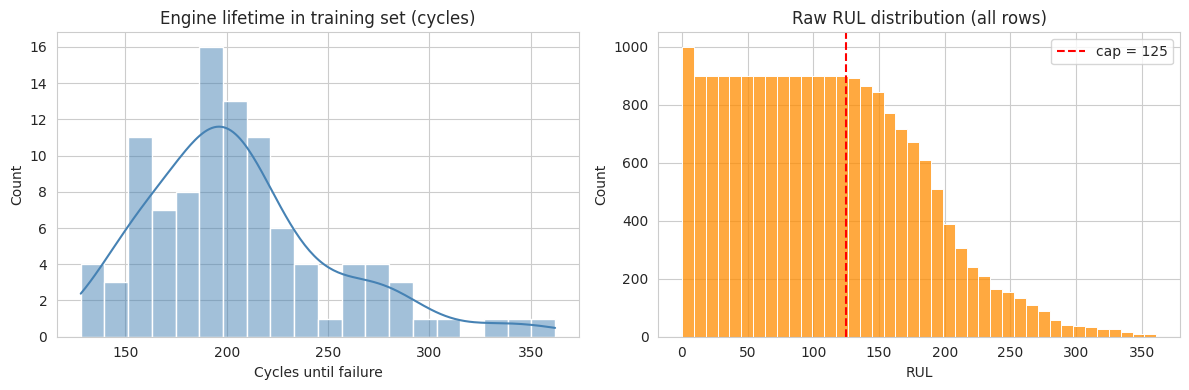

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(life, bins=20, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Engine lifetime in training set (cycles)")
ax[0].set_xlabel("Cycles until failure")

sns.histplot(train["RUL"], bins=40, ax=ax[1], color="darkorange")
ax[1].axvline(RUL_CAP, color="red", ls="--", label=f"cap = {RUL_CAP}")
ax[1].set_title("Raw RUL distribution (all rows)")
ax[1].legend()
plt.tight_layout(); plt.show()

### 3.2 Which sensors are useless? (constant columns)

In [7]:
sensor_all = [f"s{i}" for i in range(1, 22)]
std_table = train[sensor_all + ["op1", "op2", "op3"]].agg(["nunique", "std"]).T
print(std_table.round(4))

const_cols = [c for c in sensor_all if train[c].nunique() <= 1]
sensor_cols = [c for c in sensor_all if c not in const_cols]
print("\nConstant sensors removed:", const_cols)
print("Sensors kept:", sensor_cols)

     nunique      std
s1       1.0   0.0000
s2     310.0   0.5001
s3    3012.0   6.1311
s4    4051.0   9.0006
s5       1.0   0.0000
s6       2.0   0.0014
s7     513.0   0.8851
s8      53.0   0.0710
s9    6403.0  22.0829
s10      1.0   0.0000
s11    159.0   0.2671
s12    427.0   0.7376
s13     56.0   0.0719
s14   6078.0  19.0762
s15   1918.0   0.0375
s16      1.0   0.0000
s17     13.0   1.5488
s18      1.0   0.0000
s19      1.0   0.0000
s20    120.0   0.1807
s21   4745.0   0.1083
op1    158.0   0.0022
op2     13.0   0.0003
op3      1.0   0.0000

Constant sensors removed: ['s1', 's5', 's10', 's16', 's18', 's19']
Sensors kept: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


Constant sensors carry zero information, so they are dropped. The operational settings (`op1-op3`) are tiny noise in FD001 (a single operating condition), so we do not use them as features.

### 3.3 Bivariate: sensor behavior as the engine approaches failure

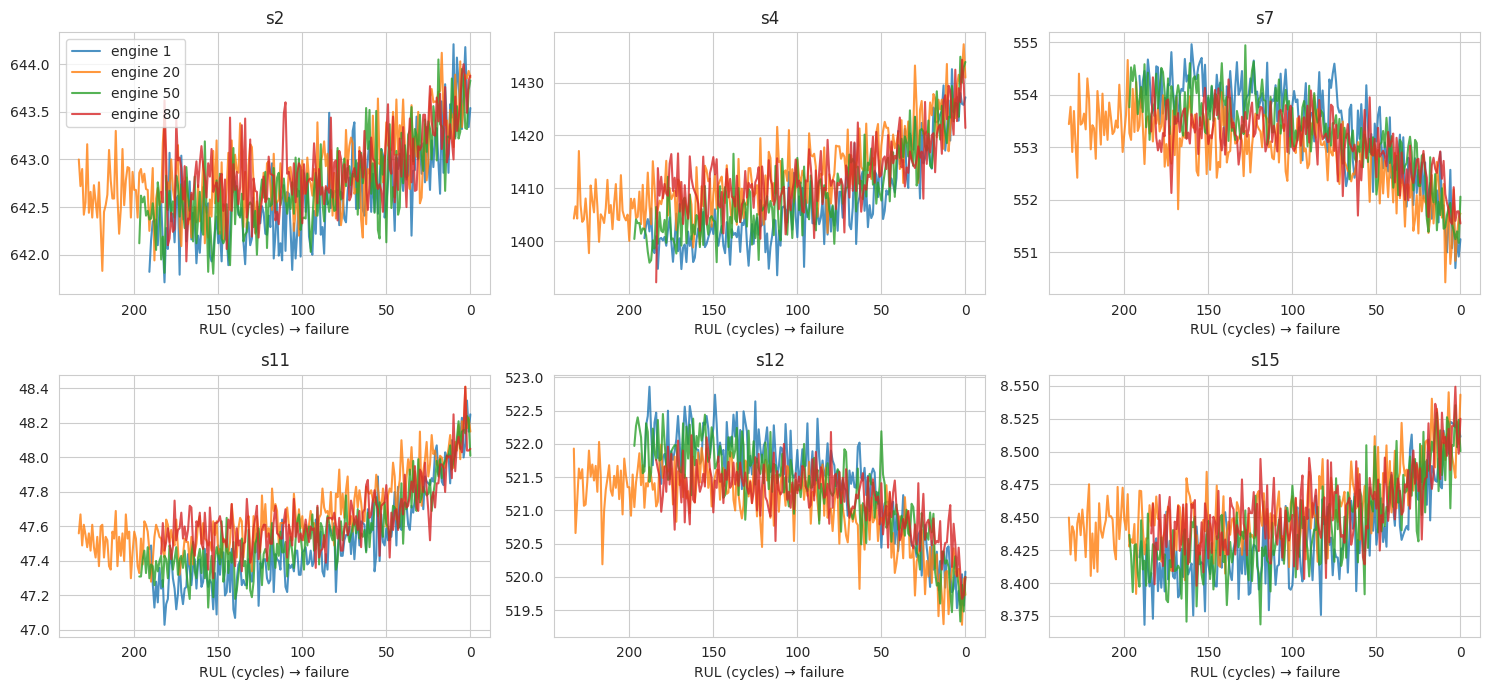

In [8]:
# Sensors that clearly drift: plot a few engines, x axis = capped RUL reversed (failure on the right)
show_sensors = ["s2", "s4", "s7", "s11", "s12", "s15"]
show_sensors = [s for s in show_sensors if s in sensor_cols]
engines = [1, 20, 50, 80]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, s in zip(axes.ravel(), show_sensors):
    for u in engines:
        d = train[train["unit"] == u]
        ax.plot(d["RUL"], d[s], alpha=0.8, label=f"engine {u}")
    ax.invert_xaxis()
    ax.set_title(s); ax.set_xlabel("RUL (cycles) → failure")
axes[0, 0].legend()
plt.tight_layout(); plt.show()

### 3.4 Multivariate: correlation with RUL and between sensors

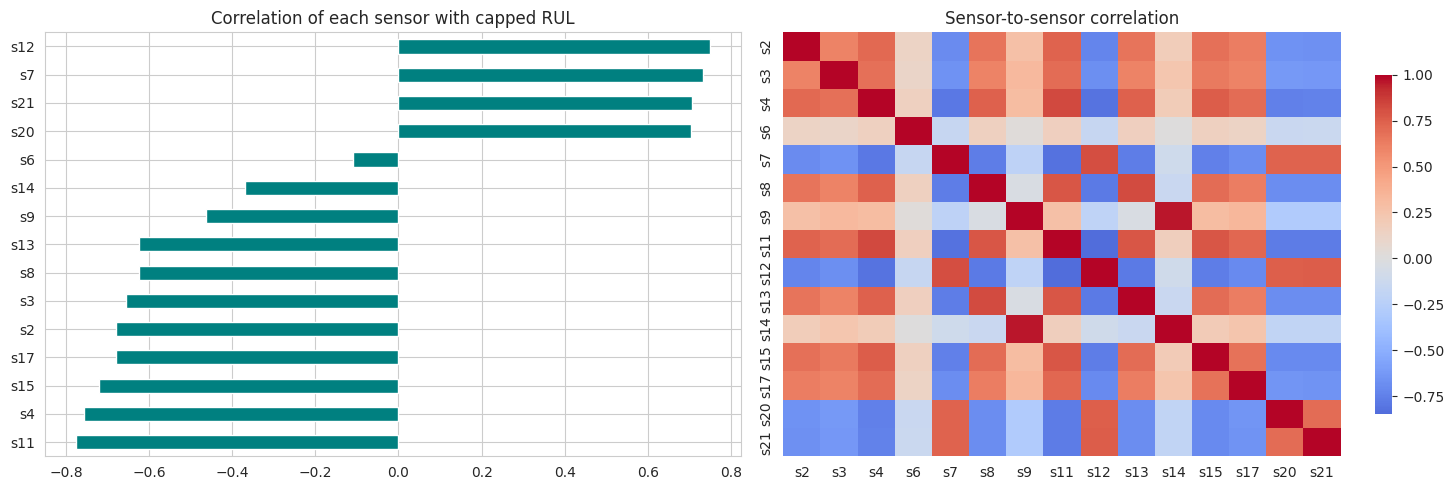

In [9]:
corr_rul = train[sensor_cols + ["RUL_capped"]].corr()["RUL_capped"].drop("RUL_capped").sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
corr_rul.plot(kind="barh", ax=ax[0], color="teal")
ax[0].set_title("Correlation of each sensor with capped RUL")

sns.heatmap(train[sensor_cols].corr(), cmap="coolwarm", center=0, ax=ax[1],
            cbar_kws={"shrink": .8})
ax[1].set_title("Sensor-to-sensor correlation")
plt.tight_layout(); plt.show()

### 3.5 Key insights (edit these after you look at YOUR charts)
1. Engines fail after very different lifetimes, so a fixed maintenance schedule must be set for the shortest-lived engines, which wastes life on the others.
2. Several sensors are perfectly constant and carry no information; they are removed.
3. A subset of sensors drifts steadily upward or downward as failure approaches, which is the degradation signal we need.
4. Many sensors are strongly correlated with each other (redundant), so regularized or tree-based models should handle this well.
5. Raw sensor readings are noisy, so **rolling averages per engine** should help the model see the trend.

## 4. Preprocessing and feature engineering
- **Rolling-window features** (mean and std of the last 10 cycles) are computed **per engine** with only *past* readings, so there is no leakage across engines or from the future.
- `cycle` (age of the engine) is also a legitimate feature at prediction time.
- **Scaling** happens inside the scikit-learn `Pipeline`, so it is fitted on training folds only.
- **Splitting:** the official train and test files are different engines, so the test set is untouched. For cross-validation we use **GroupKFold by engine**, so rows of one engine never appear in both train and validation folds.

In [10]:
WINDOW = 10

def add_rolling_features(df, sensor_cols, window=WINDOW):
    """Per-engine rolling mean/std using only current and past cycles."""
    df = df.sort_values(["unit", "cycle"]).reset_index(drop=True)
    g = df.groupby("unit")[sensor_cols]
    r_mean = g.rolling(window, min_periods=1).mean().reset_index(level=0, drop=True)
    r_std  = g.rolling(window, min_periods=1).std().reset_index(level=0, drop=True).fillna(0)
    r_mean.columns = [f"{c}_mean" for c in sensor_cols]
    r_std.columns  = [f"{c}_std"  for c in sensor_cols]
    return pd.concat([df, r_mean, r_std], axis=1)

feature_cols = (["cycle"] + sensor_cols
                + [f"{c}_mean" for c in sensor_cols]
                + [f"{c}_std" for c in sensor_cols])

train_fe = add_rolling_features(train, sensor_cols)
test_fe  = add_rolling_features(test,  sensor_cols)

X_train = train_fe[feature_cols]
y_train = train_fe["RUL_capped"]
groups  = train_fe["unit"]

# Test set: evaluate at the LAST recorded cycle of each engine (official protocol)
test_last = test_fe.groupby("unit").tail(1).reset_index(drop=True)
X_test = test_last[feature_cols]
y_test = rul_test["RUL_true"].clip(upper=RUL_CAP).values   # row i = engine i

print("Number of features:", len(feature_cols))
print("X_train:", X_train.shape, "| X_test (1 row per engine):", X_test.shape)

Number of features: 46
X_train: (20631, 46) | X_test (1 row per engine): (100, 46)


## 5. Evaluation helpers and baseline
The **NASA score** is asymmetric: `d = predicted - true`. Late predictions (`d > 0`) are penalized more heavily than early ones, because a late prediction means a possible in-service failure. Lower is better.

**Baseline:** always predict the mean RUL of the training set.

In [11]:
def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    return np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))

def evaluate(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE":  mean_absolute_error(y_true, y_pred),
        "R2":   r2_score(y_true, y_pred),
        "NASA score": nasa_score(y_true, y_pred),
    }

baseline = Pipeline([("model", DummyRegressor(strategy="mean"))])
baseline.fit(X_train, y_train)
base_res = evaluate(y_test, baseline.predict(X_test))
print("Baseline (mean) on test:", {k: round(v, 2) for k, v in base_res.items()})

Baseline (mean) on test: {'RMSE': np.float64(41.94), 'MAE': 34.83, 'R2': -0.1, 'NASA score': np.float64(33354.47)}


## 6. Modeling, cross-validation and tuning
Three algorithms from the course:
1. **Ridge regression** (linear, regularized)
2. **Random Forest**
3. **Histogram Gradient Boosting**

Each is tuned with `RandomizedSearchCV` using **GroupKFold (5 folds, grouped by engine)** on the **training data only**, optimizing RMSE.

In [13]:
cv = GroupKFold(n_splits=5)

searches = {
    "Ridge": (
        Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
        {"model__alpha": loguniform(1e-2, 1e3)}, 15),
    "RandomForest": (
        Pipeline([("scale", StandardScaler()),
                  ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
        {"model__n_estimators": [100, 200, 300],
         "model__max_depth": [8, 12, 16, None],
         "model__min_samples_leaf": [1, 5, 10, 20],
         "model__max_features": [0.3, 0.5, 1.0]}, 12),
    "HistGradBoosting": (
        Pipeline([("scale", StandardScaler()),
                  ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
        {"model__learning_rate": loguniform(0.02, 0.3),
         "model__max_iter": randint(100, 500),
         "model__max_depth": [3, 5, 7, None],
         "model__min_samples_leaf": randint(10, 100),
         "model__l2_regularization": loguniform(1e-3, 10)}, 15),
}

fitted, cv_rows = {}, []
for name, (pipe, params, n_iter) in searches.items():
    rs = RandomizedSearchCV(pipe, params, n_iter=n_iter, cv=cv,
                            scoring="neg_root_mean_squared_error",
                            random_state=RANDOM_STATE, n_jobs=-1, verbose=0)
    rs.fit(X_train, y_train, groups=groups)
    fitted[name] = rs.best_estimator_
    cv_rows.append({"Model": name, "CV RMSE": -rs.best_score_})
    print(f"{name:18s} CV RMSE = {-rs.best_score_:.2f} | best params: {rs.best_params_}")

pd.DataFrame(cv_rows).sort_values("CV RMSE")

Ridge              CV RMSE = 19.80 | best params: {'model__alpha': np.float64(214.23021757741054)}
RandomForest       CV RMSE = 16.17 | best params: {'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_features': 0.3, 'model__max_depth': 16}
HistGradBoosting   CV RMSE = 16.41 | best params: {'model__l2_regularization': np.float64(0.00678838791242122), 'model__learning_rate': np.float64(0.09304593169956206), 'model__max_depth': 3, 'model__max_iter': 290, 'model__min_samples_leaf': 27}


,Model,CV RMSE
1,RandomForest,16.171822
2,HistGradBoosting,16.410049
0,Ridge,19.799192


**Note:** CV RMSE is measured on *all rows* of held-out engines (many are healthy early-life rows at the cap), while the test metric uses only the *last recorded cycle* of each test engine. The two numbers are therefore not directly comparable. We pick the best model by **CV only** and then look at the test set.

## 7. Final evaluation on the untouched test set

In [14]:
rows = [{"Model": "Baseline (mean)", **base_res}]
test_preds = {}
for name, model in fitted.items():
    p = np.clip(model.predict(X_test), 0, RUL_CAP)
    test_preds[name] = p
    rows.append({"Model": name, **evaluate(y_test, p)})

results = pd.DataFrame(rows).round(2)
display(results)

# Final model = lowest CV RMSE
best_name = min(cv_rows, key=lambda r: r["CV RMSE"])["Model"]
final_model = fitted[best_name]
y_pred = test_preds[best_name]
print("Final model chosen by CV:", best_name)

,Model,RMSE,MAE,R2,NASA score
0,Baseline (mean),41.94,34.83,-0.10,33354.47
1,Ridge,21.24,16.48,0.72,1389.79
2,RandomForest,17.66,12.68,0.81,597.94
3,HistGradBoosting,17.68,12.55,0.81,872.44


Final model chosen by CV: RandomForest


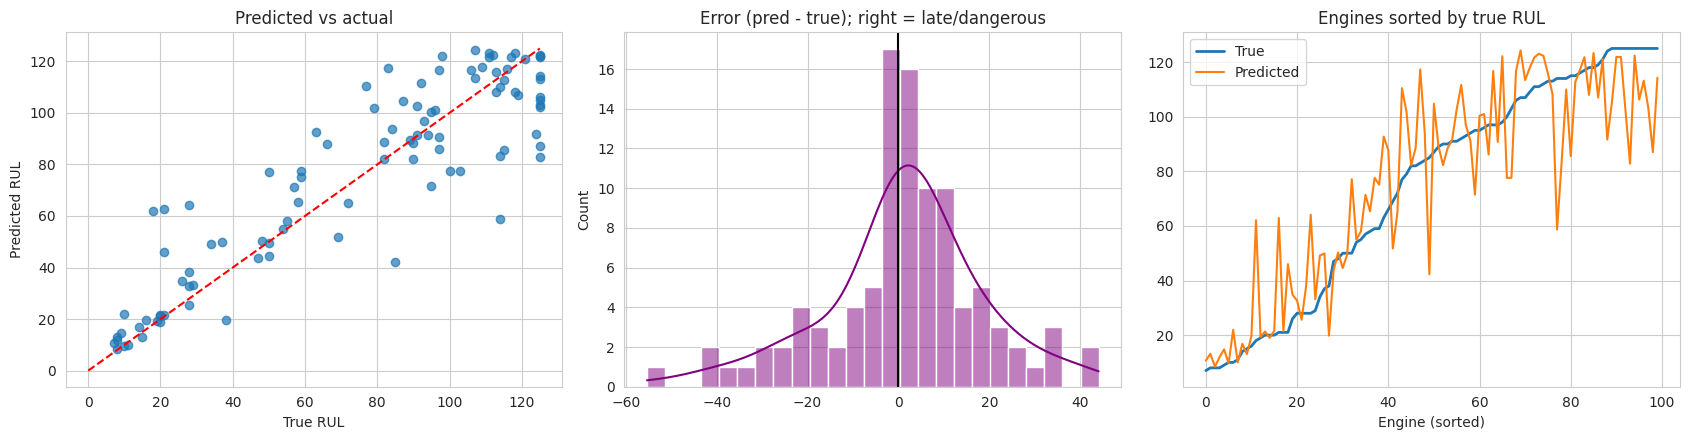

Mean error: 1.13 cycles | Late predictions (pred > true): 60% of engines


In [15]:
err = y_pred - y_test   # positive = predicted MORE life than real (dangerous)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y_test, y_pred, alpha=0.7)
ax[0].plot([0, RUL_CAP], [0, RUL_CAP], "r--")
ax[0].set_xlabel("True RUL"); ax[0].set_ylabel("Predicted RUL"); ax[0].set_title("Predicted vs actual")

sns.histplot(err, bins=25, kde=True, ax=ax[1], color="purple")
ax[1].axvline(0, color="k"); ax[1].set_title("Error (pred - true); right = late/dangerous")

order = np.argsort(y_test)
ax[2].plot(y_test[order], label="True", lw=2)
ax[2].plot(y_pred[order], label="Predicted", lw=1.5)
ax[2].set_title("Engines sorted by true RUL"); ax[2].set_xlabel("Engine (sorted)"); ax[2].legend()
plt.tight_layout(); plt.show()

print(f"Mean error: {err.mean():.2f} cycles | Late predictions (pred > true): {(err > 0).mean()*100:.0f}% of engines")

### Error analysis
Where does the model fail? Maintenance decisions matter most when the engine is **close to failure**, so we check error by true-RUL bucket and list the worst engines.

In [16]:
err_df = pd.DataFrame({"unit": test_last["unit"], "true": y_test, "pred": y_pred, "error": err})
err_df["bucket"] = pd.cut(err_df["true"], bins=[-1, 30, 60, 90, RUL_CAP],
                          labels=["0-30", "31-60", "61-90", "91-125"])

bucket_tbl = err_df.groupby("bucket").apply(lambda d: pd.Series({
    "engines": len(d),
    "RMSE": np.sqrt((d["error"]**2).mean()),
    "MAE": d["error"].abs().mean(),
    "mean error": d["error"].mean()})).round(2)
display(bucket_tbl)

print("\nTop 10 worst engines:")
display(err_df.reindex(err_df["error"].abs().sort_values(ascending=False).index).head(10).round(1))

,engines,RMSE,MAE,mean error
bucket,,,,
0-30,25.0,15.64,8.90,8.36
31-60,14.0,13.05,10.38,6.44
61-90,15.0,21.39,16.87,6.68
91-125,46.0,18.56,14.07,-6.23



Top 10 worst engines:


,unit,true,pred,error,bucket
44,45,114,58.7,-55.3,91-125
40,41,18,62.1,44.1,0-30
92,93,85,42.3,-42.7,61-90
73,74,125,82.8,-42.2,91-125
36,37,21,62.9,41.9,0-30
88,89,125,87.0,-38.0,91-125
17,18,28,64.1,36.1,0-30
14,15,83,117.3,34.3,61-90
66,67,77,110.4,33.4,61-90
11,12,124,91.6,-32.4,91-125


## 8. Stretch goal: maintenance alert
Rule: **raise an alert when predicted RUL < threshold.** The "true event" is an engine whose real RUL is below 30 cycles.
- **Recall** = of the engines really close to failure, how many did we flag? (missed alert = safety risk)
- **Precision** = of the alerts we raised, how many were real? (false alert = unnecessary maintenance cost)

,alert if pred RUL <,precision,recall,alerts raised,real at-risk engines
0,30,0.94,0.68,18,25
1,35,0.95,0.80,21,25
2,40,0.95,0.84,22,25
3,50,0.76,0.88,29,25


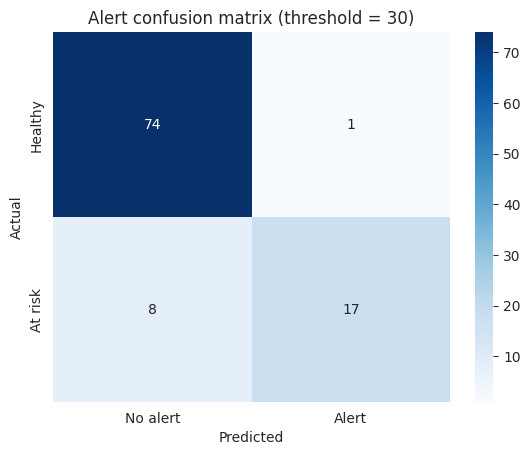

In [17]:
TRUE_LIMIT = 30
y_true_alert = (y_test < TRUE_LIMIT).astype(int)

rows = []
for thr in [30, 35, 40, 50]:
    y_alert = (y_pred < thr).astype(int)
    rows.append({"alert if pred RUL <": thr,
                 "precision": precision_score(y_true_alert, y_alert, zero_division=0),
                 "recall": recall_score(y_true_alert, y_alert, zero_division=0),
                 "alerts raised": y_alert.sum(), "real at-risk engines": y_true_alert.sum()})
display(pd.DataFrame(rows).round(2))

cm = confusion_matrix(y_true_alert, (y_pred < 30).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No alert", "Alert"], yticklabels=["Healthy", "At risk"])
plt.title("Alert confusion matrix (threshold = 30)"); plt.ylabel("Actual"); plt.xlabel("Predicted")
plt.show()

## 9. Which sensors matter? (permutation importance)
Shuffling one feature and measuring how much the error increases. A bigger increase means the feature is more important.

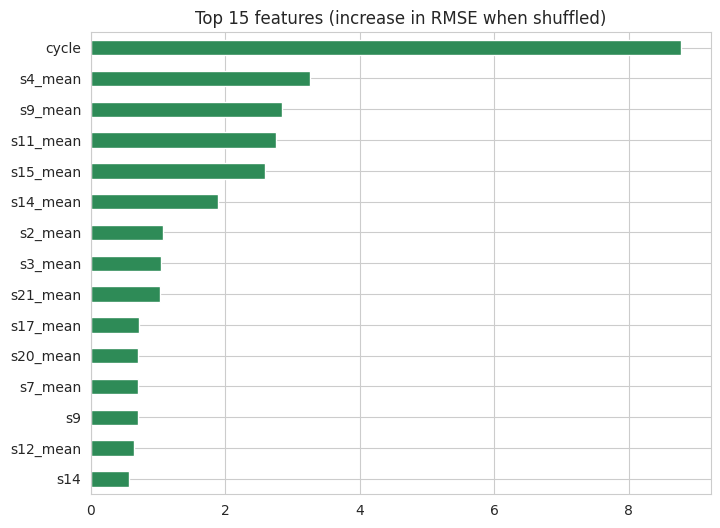

In [18]:
pi = permutation_importance(final_model, X_train.sample(3000, random_state=RANDOM_STATE),
                            y_train.loc[X_train.sample(3000, random_state=RANDOM_STATE).index],
                            scoring="neg_root_mean_squared_error",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=feature_cols).sort_values(ascending=False).head(15)

imp[::-1].plot(kind="barh", figsize=(8, 6), color="seagreen")
plt.title("Top 15 features (increase in RMSE when shuffled)")
plt.show()

## 10. Business insights and limitations 
**What the results mean**
- The best model (`Random Forest`) predicts remaining life with an error of about **17.66 cycles** (RMSE) vs **41.94** for the mean baseline.
- With a threshold of 40, the alert catches **84%** of engines within 30 cycles of failure, with **95%** precision.

**Recommendation**
- Replace fixed schedules with condition-based maintenance: schedule the shop visit when predicted RUL drops below the chosen threshold.
- Use a *safer* (higher) threshold, since a missed failure costs far more than an early inspection.
- Monitor the top sensors (`s4_mean`, `s9_mean`, `s11_mean`) first, because they carry most of the degradation signal.

**Limitations**
- Simulated data (FD001): a single operating condition and a single fault mode; real engines are messier.
- Only 100 training engines, so estimates have high variance.
- The 125-cycle cap means the model cannot say how healthy an engine is *beyond* 125 cycles.
- The model needs at least a few cycles of history per engine.

## 11. Save the pipeline for the web app

In [19]:
os.makedirs("/kaggle/working", exist_ok=True)

joblib.dump(final_model, "/kaggle/working/rul_pipeline.joblib")

meta = {"feature_cols": feature_cols, "sensor_cols": sensor_cols,
        "window": WINDOW, "rul_cap": RUL_CAP, "model_name": best_name,
        "sklearn_version": sklearn.__version__}
with open("/kaggle/working/meta.json", "w") as f:
    json.dump(meta, f)

# Small demo file for the app: raw sensor history of 10 test engines
demo = test[test["unit"].isin(range(1, 11))]
demo.to_csv("/kaggle/working/demo_engines.csv", index=False)

print("Saved. scikit-learn version for requirements.txt:", sklearn.__version__)
print(os.listdir("/kaggle/working"))

Saved. scikit-learn version for requirements.txt: 1.6.1
['rul_pipeline.joblib', 'meta.json', 'demo_engines.csv', '.virtual_documents']
